In [1]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import pandas as pd
#import function as my
import torch.nn as nn
import time as tm
import matplotlib.pyplot as plt

from tqdm import tqdm

# Set this to the number of physical cores you will use
num_threads = 10
tc.set_num_threads(num_threads)
tc.set_num_interop_threads(num_threads)
print(f"Threads set to: {tc.get_num_threads()}")

Threads set to: 10


In [2]:
tfinal      = 3.0
N           = 500
Nedo=16
Nfield=2
t_points=np.linspace(0,tfinal,N)

Run this if you DO NOT want to use the frequency extended range.

In [3]:
import torch.nn as nn
from torch.optim.lr_scheduler import StepLR
from tqdm import tqdm


class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1, creat_p=False, N_of_paramater=1, dropout_prob=0.0):
        super().__init__()
        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob

        # input camada linear
        self.hidden_layers = nn.ModuleList([nn.Linear(input_, neuronio[0])])
        # camadas do meio
        self.hidden_layers.extend([nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(self.neuronio)-1)])
        # Última camada linear
        self.output_layer = nn.Linear(neuronio[-1], output_)

        # Função de ativação
        self.activation_ = activation

        # Camadas de Dropout
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(self.neuronio))])

        # Criar o parâmetro
        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)
        x = self.output_layer(x)
        return x

class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)



In [4]:
neuronio = [128,128,128]
X_vector   = Rede(
    neuronio    = neuronio,
    input_      = 1,
    output_     = Nedo+Nfield,
    activation  =[tc.nn.Tanh()]*len(neuronio),
    creat_p     =True,
    N_of_paramater= 0)
opt = tc.optim.Adam(X_vector.parameters(),
        lr = 0.001)
time =  tc.linspace(
        0,
        tfinal,
        N,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))
#index_data = np.random.randint(0,N,size=100)
# X_vector.parametro

Run this if you do want to use the extended frequency range.

In [38]:
def inv_sigmoid(y):
    eps = 1e-6
    y = tc.clamp(y, eps, 1 - eps)
    return tc.log(y / (1 - y))

class FourierFeatures(nn.Module):
    def __init__(self, n_freq, f_max, trainable=True):
        super().__init__()
        self.f_max = f_max
        self.raw_freq = nn.Parameter(tc.randn(n_freq), requires_grad=trainable)

        f0 = tc.linspace(0.05 * f_max, 0.95 * f_max, n_freq)
        raw0 = inv_sigmoid(f0 / f_max)

        self.raw_freq = nn.Parameter(raw0.clone(), requires_grad=trainable)

    def get_freq(self):
        return self.f_max * tc.sigmoid(self.raw_freq)

    def forward(self, t):
        if t.dim() == 1:
            t = t.unsqueeze(1)   # (batch,1)

        freq = self.get_freq().unsqueeze(0)   # (1,n_freq)
        arg = 2.0 * np.pi * t * freq        # (batch,n_freq)

        return tc.cat([tc.sin(arg), tc.cos(arg)], dim=1)
    
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=16, f_max=20.0):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=True)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [53]:
neuronio = [128, 128]

X_vector = Rede(
    neuronio=neuronio,
    input_=1,
    output_=Nedo + Nfield,
    activation=[SIN()]*len(neuronio),
    creat_p=True,
    N_of_paramater=0,
    use_fourier=True,
    n_freq=16,
    f_max=15.0
)

opt = tc.optim.Adam(X_vector.parameters(),
        lr = 0.001)
time =  tc.linspace(
        0,
        tfinal,
        N,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))

In [5]:
J22=0;J33=0;J44=6.79
from qutip import *
zero = basis(4, 0)
one = basis(4, 1)
two= basis(4, 2)
three= basis(4, 3)
def evolution_qutip(wp,ws,t_points,psi0):
    # Create atomic operators (projection and transition operators)
    sig00 = zero * zero.dag()   # |0><0|
    sig11 =one *one.dag()    # |1><1|
    sig22 = two * two.dag() # |2><2|
    sig33 = three * three.dag() # |3><3|
    sig01 = zero * one.dag()   # |0><1|
    sig02 = zero * two.dag() # |0><2|
    sig12 = one * two.dag()   # |1><2|
    sig21 = two * one.dag() # |2><1|
    sig10 = one *zero.dag()   # |1><0|
    sig20 = two *zero.dag() # |2><0|
    sig03 = zero * three.dag()   # |0><3|
    sig30 = three * zero.dag()   # |3><0|
    sig13 = one * three.dag()   # |1><3|
    sig31 = three * one.dag()   # |3><1|
    H0 = J44*sig33
    H1 =(sig02+sig03)+(sig20+sig30)
    H2 =(sig12-sig13)+(sig21-sig31)
    # The full Hamiltonian is defined as a list:
    # H = H0 + f(t) * H1, where f(t) is the field data
    H = [H0, [H1,wp], [H2,ws]] # QuTiP uses cubic spline interpolation for field_data

    # (Optional) Define collapse operators for an open system simulation
    c_ops = [] # e.g., c_ops = [np.sqrt(gamma) * qt.sigmam()]

    # 3. Define the initial state and expectation value operators
    #psi0 = qt.basis(4, 0) # Initial state |0>
    # psi0 = 1/np.sqrt(2)*(qt.basis(4, 0)+qt.basis(4, 1)) # Initial state |0>
    e_ops = [] # Operators for which to calculate expectation values
    tlist= t_points

    # 4. Simulate the time evolution
    # Use mesolve for master equation dynamics (works for closed systems too if c_ops is empty)
    result = qt.mesolve(H, psi0,tlist, c_ops,e_ops=e_ops)
    real_parts = []
    imag_parts = []

    for state in result.states:
        # .full() converte o Qobj em um array numérico do NumPy
        state_array = state.full()

        real_parts.append(np.real(state_array))
        imag_parts.append(np.imag(state_array))

    # Convertendo em arrays do NumPy para facilitar a manipulação posterior
    # Formato resultante: (num_passos_temporais, N, 1) para kets
    real_parts = np.array(real_parts)
    imag_parts = np.array(imag_parts)

    return real_parts,imag_parts


def guess(time):
    return 1 + np.sin(2*np.pi*time*2.5/tfinal)
def guess1(time):
    return 1 - np.cos(2*np.pi*time*2.5/tfinal)
wp=guess(t_points)
ws=guess1(t_points)
psi0 = qt.basis(4, 0) # Initial state |0>
re,im=evolution_qutip(wp,ws,t_points,psi0)
psi0 = qt.basis(4, 1) # Initial state |1>
re1,im1=evolution_qutip(wp,ws,t_points,psi0)


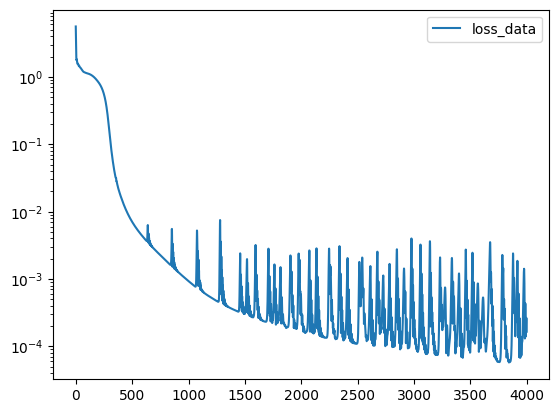

In [6]:
# Convertemos para float32 e forçamos o formato (N, 1) para evitar broadcasting incorreto
im_00 = tc.tensor(im[:, 0, 0], dtype=tc.float32).view(-1, 1)
im_10 = tc.tensor(im[:, 1, 0], dtype=tc.float32).view(-1, 1)
im_20 = tc.tensor(im[:, 2, 0], dtype=tc.float32).view(-1, 1)
im_30 = tc.tensor(im[:, 3, 0], dtype=tc.float32).view(-1, 1)
re_00 = tc.tensor(re[:, 0, 0], dtype=tc.float32).view(-1, 1)
re_10 = tc.tensor(re[:, 1, 0], dtype=tc.float32).view(-1, 1)
re_20 = tc.tensor(re[:, 2, 0], dtype=tc.float32).view(-1, 1)
re_30 = tc.tensor(re[:, 3, 0], dtype=tc.float32).view(-1, 1)


im1_00 = tc.tensor(im1[:, 0, 0], dtype=tc.float32).view(-1, 1)
im1_10 = tc.tensor(im1[:, 1, 0], dtype=tc.float32).view(-1, 1)
im1_20 = tc.tensor(im1[:, 2, 0], dtype=tc.float32).view(-1, 1)
im1_30 = tc.tensor(im1[:, 3, 0], dtype=tc.float32).view(-1, 1)
re1_00 = tc.tensor(re1[:, 0, 0], dtype=tc.float32).view(-1, 1)
re1_10 = tc.tensor(re1[:, 1, 0], dtype=tc.float32).view(-1, 1)
re1_20 = tc.tensor(re1[:, 2, 0], dtype=tc.float32).view(-1, 1)
re1_30 = tc.tensor(re1[:, 3, 0], dtype=tc.float32).view(-1, 1)
target_field_p = tc.tensor(wp, dtype=tc.float32).view(-1, 1)
target_field_s = tc.tensor(ws, dtype=tc.float32).view(-1, 1)

epocas  = 4000
LOSS    = []
LOSS1   = []
LOSS2   = []
pi=tc.tensor([np.pi])

for _ in (range(epocas)):
    ####### Forward pass #######
    y  = X_vector(time)
    # Com os tensores alinhados em (N, 1), a subtração funciona ponto a ponto corretamente
    LOSS_data  =  (y[:, 0:1] - re_00)**2
    LOSS_data +=  (y[:, 1:2] - im_00)**2
    LOSS_data +=  (y[:, 2:3] - re_10)**2
    LOSS_data +=  (y[:, 3:4] - im_10)**2
    LOSS_data +=  (y[:, 4:5] - re_20)**2
    LOSS_data +=  (y[:, 5:6] - im_20)**2
    LOSS_data +=  (y[:, 6:7] - re_30)**2
    LOSS_data +=  (y[:, 7:8] - im_30)**2

    LOSS_data +=  (y[:, 8:9] - re1_00)**2
    LOSS_data +=  (y[:, 9:10] - im1_00)**2
    LOSS_data +=  (y[:, 10:11] - re1_10)**2
    LOSS_data +=  (y[:, 11:12] - im1_10)**2
    LOSS_data +=  (y[:, 12:13] - re1_20)**2
    LOSS_data +=  (y[:, 13:14] - im1_20)**2
    LOSS_data +=  (y[:, 14:15] - re1_30)**2
    LOSS_data +=  (y[:, 15:16] - im1_30)**2
    
    LOSS_data += (y[:, 16:17] - target_field_p)**2
    LOSS_data += (y[:, 17:18] - target_field_s)**2
    LOSS_data=LOSS_data.mean()
    
    ####### Loss total #######
    loss_i =  LOSS_data

    ####### Backpropagation #######
    opt.zero_grad()
    loss_i.backward()
    opt.step()
    LOSS2.append(LOSS_data.cpu().detach().numpy())
    LOSS.append(loss_i.cpu().detach().numpy())


plt.plot(LOSS2,label="loss_data")
plt.yscale("log")
plt.legend()
plt.show()


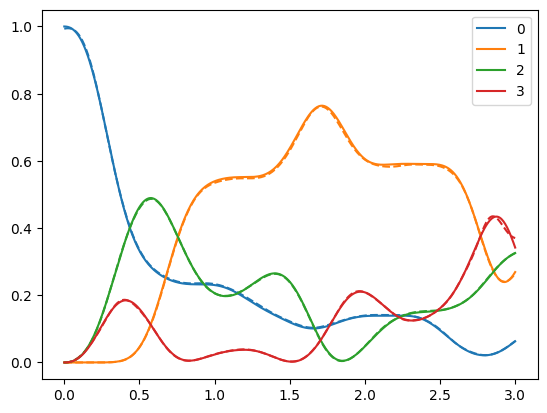

In [7]:
X_  = X_vector(time).detach().numpy()
plt.plot(t_points,X_[:,0]**2+X_[:,1]**2, 'tab:blue', linestyle='dashed')
plt.plot(t_points,X_[:,2]**2+X_[:,3]**2, linestyle='dashed', color='tab:orange')
plt.plot(t_points,X_[:,4]**2+X_[:,5]**2, 'tab:green', linestyle='dashed'      )
plt.plot(t_points,X_[:,6]**2+X_[:,7]**2, 'tab:red', linestyle='dashed')

plt.plot(t_points,im[:, 0, 0]**2+re[:, 0, 0]**2, 'tab:blue', label="0")
plt.plot(t_points,im[:, 1, 0]**2+re[:, 1, 0]**2, color='tab:orange', label="1")
plt.plot(t_points,im[:, 2, 0]**2+re[:, 2, 0]**2, 'tab:green', label="2")
plt.plot(t_points,im[:, 3, 0]**2+re[:, 3, 0]**2, 'tab:red', label="3")
plt.legend()
plt.show()

In [8]:
#Make the calculation of all the loss functions compilable
@tc.jit.script
def calculate_all_losses(s0: tc.Tensor, s1: tc.Tensor, derivs: tc.Tensor, v0: tc.Tensor, vt: tc.Tensor, Op: tc.Tensor, Os: tc.Tensor):
    J22=0;J33=0;J44=6.79
    
    drift = derivs   # (N,16)
    drift = drift.reshape(-1, 8, 2)#view(-1, 8, 2)
    dx = drift[..., 0]
    dy = drift[..., 1]

    Y = tc.cat([s0, s1], dim=1)
    Y = Y.reshape(-1, 8, 2)#view(-1, 8, 2)

    X = Y[..., 0]  # (N, 8)
    Yc = Y[..., 1] # (N, 8)

    rhs_x = tc.zeros_like(dx)
    rhs_y = tc.zeros_like(dy)

    # indices:
    # 0→00, 1→10, 2→20, 3→30, 4→01, 5→11, 6→21, 7→31

    # ---- first 4 sites ----
    rhs_x[:,0] =  (Op[:,0] * (Yc[:,2] + Yc[:,3]))
    rhs_y[:,0] = -(Op[:,0] * (X[:,2] + X[:,3]))

    rhs_x[:,1] =  (J22 * Yc[:,1] + Os[:,0]*(Yc[:,2] - Yc[:,3]))
    rhs_y[:,1] = -(J22 * X[:,1] + Os[:,0]*(X[:,2] - X[:,3]))

    rhs_x[:,2] =  (J33 * Yc[:,2] + Op[:,0]*Yc[:,0] + Os[:,0]*Yc[:,1])
    rhs_y[:,2] = -(J33 * X[:,2] + Op[:,0]*X[:,0] + Os[:,0]*X[:,1])

    rhs_x[:,3] =  (J44 * Yc[:,3] + Op[:,0]*Yc[:,0] - Os[:,0]*Yc[:,1])
    rhs_y[:,3] = -(J44 * X[:,3] + Op[:,0]*X[:,0] - Os[:,0]*X[:,1])

    rhs_x[:,4] =  (Op[:,0] * (Yc[:,6] + Yc[:,7]))
    rhs_y[:,4] = -(Op[:,0] * (X[:,6] + X[:,7]))

    rhs_x[:,5] =  (J22 * Yc[:,5] + Os[:,0]*(Yc[:,6] - Yc[:,7]))
    rhs_y[:,5] = -(J22 * X[:,5] + Os[:,0]*(X[:,6] - X[:,7]))

    rhs_x[:,6] =  (J33 * Yc[:,6] + Op[:,0]*Yc[:,4] + Os[:,0]*Yc[:,5])
    rhs_y[:,6] = -(J33 * X[:,6] + Op[:,0]*X[:,4] + Os[:,0]*X[:,5])

    rhs_x[:,7] =  (J44 * Yc[:,7] + Op[:,0]*Yc[:,4] - Os[:,0]*Yc[:,5])
    rhs_y[:,7] = -(J44 * X[:,7] + Op[:,0]*X[:,4] - Os[:,0]*X[:,5])

    loss_edo = ((dx - rhs_x)**2 + (dy - rhs_y)**2).mean()

    ####### leakage loss #######
    idx = tc.tensor([2, 3, 6, 7], device=X.device)
    loss_state = (X[:, idx]**2 + Yc[:, idx]**2).mean()

    # ---- initial-condition loss -------------------------------------------
    X_in = X[0]   # (8,)
    Y_in = Yc[0]  # (8,)

    loss_data = (X_in * v0[::2] + Y_in * v0[1::2]).sum()
    loss_data = tc.abs(1. - loss_data/2.)

    ######## loss data(target conditions) #######
    X_T = X[-1]   # (8,)
    Y_T = Yc[-1]  # (8,)

    loss_gate = (X_T * vt[::2] + Y_T * vt[1::2]).sum()
    loss_gate = tc.abs(1. - loss_gate/2.)

    return loss_edo, loss_data, loss_gate, loss_state

100%|█████████████████████████████████████| 20000/20000 [13:35<00:00, 24.53it/s]


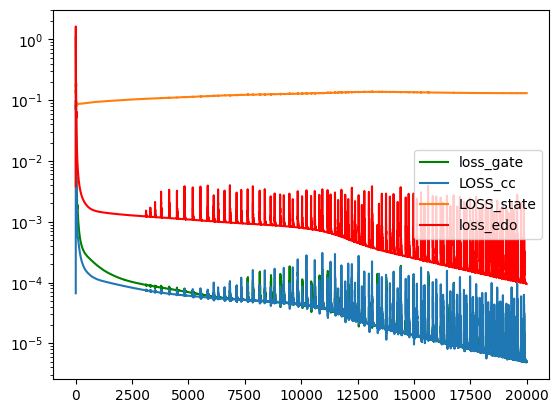

In [9]:
epocas  = 20000
sqrt12=1.0/tc.sqrt(tc.tensor(2.0))
LOSS    = []
LOSS1   = []
LOSS2   = []
LOSS3   = []
hisorty_of_param = []
one=tc.ones(Nedo)

#The order is R00 I00 R10 I10 R20 I20 R30 I30 R01 I01 R11 I11 R21 I21 R31 I31
#              0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15
v0=tc.zeros(Nedo)
vt=tc.zeros(Nedo)

#porta X: initial states are e^(i pi/4) |0> and e^(-i pi/4) |1>
#v0[0]=sqrt12; v0[1]=sqrt12; v0[10]=sqrt12; v0[11]=-sqrt12
#vt[2]=sqrt12; vt[3]=sqrt12; vt[8]=sqrt12; vt[9]=-sqrt12

#porta Hadamard: initial states are |0> and |1>
v0[0]=1.0; v0[10]=1.0
vt[0]=sqrt12; vt[2]=sqrt12; vt[8]=sqrt12; vt[10]=-sqrt12
#v0[0]=sqrt12; v0[1]=sqrt12; v0[10]=sqrt12; v0[11]=-sqrt12
#vt[0]=0.5; vt[1]=0.5; vt[2]=0.5; vt[3]=0.5; vt[8]=0.5; vt[9]=-0.5; vt[10]=-0.5; vt[11]=0.5

#porta S: initial states are e^(i pi/4) |0> and e^(-i pi/4) |1>
#v0[0]=sqrt12; v0[1]=sqrt12; v0[10]=sqrt12; v0[11]=-sqrt12
#vt[0]=sqrt12; vt[1]=sqrt12; vt[10]=sqrt12; vt[11]=sqrt12

for _ in tqdm(range(epocas)):
    ####### Forward pass #######
    y  = X_vector(time)

    # ---- split & normalise ------------------------------------------------
    state0 = y[:, :8]
    state1 = y[:, 8:16] 
    
    Op=y[:, 16:17]
    Os=y[:, 17:18]

    norma  = tc.sqrt((state0**2).sum(1, keepdim=True) + 1e-8)   # (N,1)
    norma1 = tc.sqrt((state1**2).sum(1, keepdim=True) + 1e-8)   # (N,1)
    
    s0 = state0 / norma               # (N,6) normalised
    s1 = state1 / norma1              # (N,6) normalised
    
    # keep the same 18-tuple interface for calculate_physics_loss
    regys = (*s0.split(1, dim=1), *s1.split(1, dim=1), Op, Os)

    # If time is (N,1), autograd returns (N,1); expand via the Jacobian trick:
    # We still need per-component derivatives, so keep the loop-free cat approach:
    vars_list = list(s0.split(1, dim=1)) + list(s1.split(1, dim=1))  # 12 × (N,1)
    derivs = tc.cat(
        [tc.autograd.grad(v, time, grad_outputs=tc.ones_like(v),
                          create_graph=True)[0] for v in vars_list],
        dim=1
    )  

    LOSS_edo, LOSS_cc, Loss_gate, Loss_state = calculate_all_losses(s0, s1, derivs, v0, vt, Op, Os)

    #Loss_freq = ((tc.autograd.grad(Op, time, grad_outputs=tc.ones_like(Os), create_graph=True)[0])**2).mean()
    #Loss_freq += ((tc.autograd.grad(Os, time, grad_outputs=tc.ones_like(Op), create_graph=True)[0])**2).mean()

    ####### Loss total #######
    loss_i = LOSS_edo + LOSS_cc + Loss_gate# + 0.2*Loss_state + 0.05*((((Op[1:]-Op[:-1])/time[1])**2).mean() + (((Os[1:]-Os[:-1])/time[1])**2).mean())#((Op**2).mean() + (Os**2).mean())

    ####### Backpropagation #######
    opt.zero_grad()
    loss_i.backward()
    opt.step()
    LOSS1.append(LOSS_edo.cpu().detach().numpy())
    LOSS2.append(LOSS_cc.cpu().detach().numpy())
    LOSS3.append(Loss_state.cpu().detach().numpy())
    LOSS.append(Loss_gate.cpu().detach().numpy())

plt.plot(LOSS,"g",label="loss_gate")
plt.plot(LOSS2,label="LOSS_cc")
plt.plot(LOSS3,label="LOSS_state")
plt.plot(LOSS1,'r-',label="loss_edo")
plt.yscale("log")
plt.legend()
plt.show()


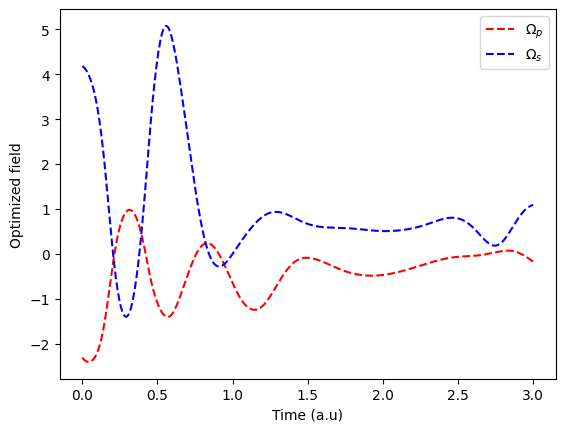

In [10]:
t_points =  np.linspace(0,tfinal, N)
X_  = X_vector(time).detach().numpy()
plt.plot(t_points,X_[:,16],"r--", label=r'$\Omega_p$')
plt.plot(t_points,X_[:,17],"b--", label=r'$\Omega_s$')
plt.xlabel('Time (a.u)')
plt.ylabel('Optimized field')
plt.legend()
plt.show()



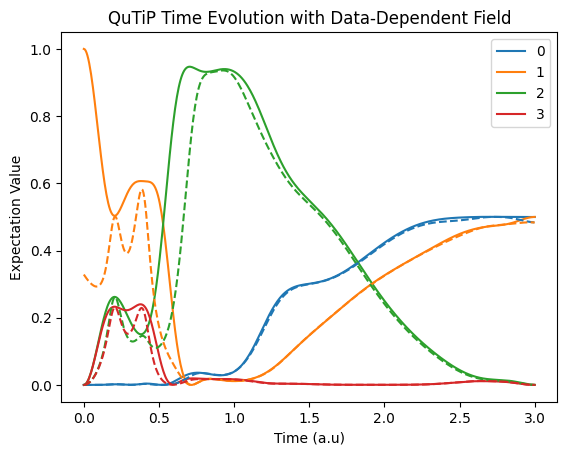

In [16]:
# QuTiP uses basis(N, n) where N is the total levels and n is the state index (starting from 0)
from qutip import *
zero = basis(4, 0)
one = basis(4, 1)
two= basis(4, 2)
three= basis(4, 3)

# Create atomic operators (projection and transition operators)
sig00 = zero * zero.dag()   # |0><0|
sig11 =one *one.dag()    # |1><1|
sig22 = two * two.dag() # |2><2|
sig33 = three * three.dag() # |3><3|
sig01 = zero * one.dag()   # |0><1|
sig02 = zero * two.dag() # |0><2|
sig12 = one * two.dag()   # |1><2|
sig21 = two * one.dag() # |2><1|
sig10 = one *zero.dag()   # |1><0|
sig20 = two *zero.dag() # |2><0|
sig03 = zero * three.dag()   # |0><3|
sig30 = three * zero.dag()   # |3><0|
sig13 = one * three.dag()   # |1><3|
sig31 = three * one.dag()   # |3><1|
H0 = J44*sig33
H1 =(sig02+sig03)+(sig20+sig30)
H2 =(sig12-sig13)+(sig21-sig31)
wp=X_[:,16]
ws=X_[:,17]
# The full Hamiltonian is defined as a list:
# H = H0 + f(t) * H1, where f(t) is the field data
H = [H0, [H1,wp], [H2,ws]] # QuTiP uses cubic spline interpolation for field_data

# (Optional) Define collapse operators for an open system simulation
c_ops = [] # e.g., c_ops = [np.sqrt(gamma) * qt.sigmam()]

# 3. Define the initial state and expectation value operators
selst = 1
psi0 = qt.basis(4, selst) # Initial state |0>
#psi0 = 1/np.sqrt(2)*(qt.basis(4, 0)+qt.basis(4, 1)) # Initial state |0>
e_ops = [sig00, sig11, sig22, sig33] # Operators for which to calculate expectation values
tlist= t_points

# 4. Simulate the time evolution
# Use mesolve for master equation dynamics (works for closed systems too if c_ops is empty)
result = qt.mesolve(H, psi0,tlist, c_ops,e_ops=e_ops)

norsq = np.sum(X_[:,:8]**2, axis=1) if selst==0 else np.sum(X_[:,8:]**2, axis=1)
plt.figure()
plt.plot(t_points,result.expect[0], label='0')
plt.plot(t_points,result.expect[1], label='1')
plt.plot(t_points,result.expect[2], label='2')
plt.plot(t_points,result.expect[3], label='3')
plt.plot(t_points,(X_[:,0+8*selst]**2+X_[:,1+8*selst]**2)/norsq, 'tab:blue', linestyle='dashed')
plt.plot(t_points,(X_[:,2+8*selst]**2+X_[:,3+8*selst]**2)/norsq, linestyle='dashed', color='tab:orange')
plt.plot(t_points,(X_[:,4+8*selst]**2+X_[:,5+8*selst]**2)/norsq, 'tab:green', linestyle='dashed'      )
plt.plot(t_points,(X_[:,6+8*selst]**2+X_[:,7+8*selst]**2)/norsq, 'tab:red', linestyle='dashed')


plt.xlabel('Time (a.u)')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('QuTiP Time Evolution with Data-Dependent Field')
plt.show()


In [13]:
print(result.expect[0][-1])
print(result.expect[1][-1])

0.5000746453852372
0.4997336931630176


In [14]:
merged = np.vstack((t_points, X_[:,16], X_[:,17]))    
df_from_numpy = pd.DataFrame(merged.T)

# Exporting the NumPy-based DataFrame
df_from_numpy.to_csv('../PopsCtrl/Data/OptField_PINN_H_GATE_4L.csv', index=False, header=['Time'] + ['Omega_p'] + ['Omega_s'])